In [1]:
# Use jax to compute
import jax
import jax.numpy as jnp
# using dataclass to store data
from dataclasses import dataclass

# pre-defined orbitals
orbital_list = ['s','p','d','f']

# using double precision
jax.config.update("jax_enable_x64", True)
default_type_complex = jnp.complex128
default_type_real = jnp.float64



# utilty

In [2]:
#utilty ================================ BEGIN

# fermi-dirac funtion
def fermi_dirac(E,mu,kBT) -> float:
    return 1.0/(jnp.exp((E-mu)/kBT)+1)
# vamp it, E is an array, in  shape of (nE,), 
# return an F-D distrubution of a whole range of E
fermi_dirac_vamp = jax.vmap(fermi_dirac,in_axes=(0,None,None))

# calculate difference matrix
# only need to be computed once
def cal_center_matrix(center_list):
    '''
    param center_list: wannier center list, 2D array, shape (nwan,3)
    return: wannier center difference matrix, 3D array, shape (nwan,nwan,3)

    matrix[i,j] = vec[i] - vec[j]
    '''
    # check input
    assert center_list.ndim == 2, "center_list must be a 2D array"  
    assert center_list.shape[1] == 3, "center_list must have shape (nwan, 3)"
    # calculate wannier center difference matrix
    center_matrix = center_list[:, None, :] - center_list[None, :, :]
    return center_matrix

# find EF from .scf.out or .nscf.out file
def find_EF(file_name: str) -> float:
    '''
    param file_name: name of the .scf.out or .nscf.out file
    return: Fermi energy
    '''
    with open(file_name, "r") as f:
        lines = f.readlines()
    for line in lines:
        if "the Fermi energy is" in line:
            EF = float(line.split()[-2])
            break
    return EF

#utilty ================================ END

In [3]:
# test EF
print (find_EF("Cu.scf.out"))


12.43


# data class

In [4]:
# data class========================= BEGIN
@dataclass
class TB_model:
    HR: jnp.ndarray = None # (nR ,nwan,nwan)
    cell_center: jnp.ndarray = None # (nR,3)
    real_lattice: jnp.ndarray = None # (3,3)
    recip_lattice: jnp.ndarray = None # (3,3)
    center_list: jnp.ndarray = None # (nwan,3)
    AA_R: jnp.ndarray = None # (nR,nwan,nwan,3)




    # post init: calculate some useful quantities
    def __post_init__(self):
        self.EF = 0.0

        self.nwan = self.HR.shape[-1] # number of wannier functions
        self.nR = self.HR.shape[0] # number of R points
        self.center_matrix = cal_center_matrix(self.center_list) # (nwan,nwan,3)

        b1 = self.recip_lattice[0]
        b2 = self.recip_lattice[1]
        b3 = self.recip_lattice[2]
        self.V = jnp.dot(b1,jnp.cross(b2,b3)) # volume of a reciprocal lattice cell
        
        # operator list
        self.O_list_inner: dict = {} # list of operators
        self.O_list_kubo: dict = {} # list of operator names    
        
        # print some info
        print (f"TB_model: nwan={self.nwan}, nR={self.nR}")
        
    
    def set_EF(self, file_name: str):
        self.EF = find_EF(file_name)
        print (f"EF={self.EF}")

    def set_E_fermis(self,
                      E_btm:float=-5,
                      E_top:float=5,
                      interval:float=0.05
                      ):  
        self.E_fermis = jnp.arange(self.EF+E_btm,self.EF+E_top,interval)
        print(f'set E_fermis from {self.EF+E_btm:.3f} to {self.EF+E_top:.3f}, interval {interval:.3f}, {len(self.E_fermis)} levels')
         

    def add_operator_kubo(self,operator: jnp.ndarray, name: str):
        '''
        add an operator to the model, and check its shape
        param O: operator matrix, shape (nwan,nwan)
        '''
        # check shape
        if operator.shape != (self.nwan,self.nwan):
            raise ValueError(f"operator {name} shape {operator.shape} not match nwan={self.nwan}")        
        self.O_list_kubo[name] = operator
        print (f"add operator {name} in kubo list")

    def add_operator_inner(self,operator: jnp.ndarray, name: str):
        '''
        add an operator to the model, and check its shape
        param O: operator matrix, shape (nwan,nwan)
        '''
        # check shape
        if operator.shape != (self.nwan,self.nwan):
            raise ValueError(f"operator {name} shape {operator.shape} not match nwan={self.nwan}")        
        self.O_list_inner[name] = operator
        print (f"add operator {name} in inner list")



    def clear_operator(self, category: str="all"):
        '''
        clear all operators in the model
        '''
        if category == "kubo":
            self.O_list_kubo = {}
            print (f"clear all operators in kubo list")
        elif category == "inner":
            self.O_list_inner = {}
            print (f"clear all operators in inner list")
        elif category == "all":
            self.O_list_kubo = {}
            self.O_list_inner = {}
            print (f"clear all operators in kubo list and inner list")
        else:
            raise ValueError(f"category {category} not supported")




In [32]:



model = read_TB_model("TB.npz")

model.add_operator_inner(jnp.eye(model.nwan), "I")

S,L,LS = build_operator_LS(['spd'])
print(L.shape)
model.add_operator_kubo(L[:,:,2], "Lz")



print (f"kubo operators: {model.O_list_kubo.keys()}")
print (f"inner operators: {model.O_list_inner.keys()}")

Oarray = jnp.array(list(model.O_list_inner.values()))
print(len(model.O_list_inner.keys()))

model.set_EF("Cu.scf.out")
model.set_E_fermis(-10,8,0.05)

kps = build_k_mesh(model,50,50,50)
my_calculator = make_calc_kubo(model,kbT = 0.026)
calculator_vmap = jax.vmap(my_calculator, in_axes=(0,))




read_TB_model: read TB.npz
TB_model: nwan=18, nR=617
add operator I in inner list
(18, 18, 3)
add operator Lz in kubo list
kubo operators: dict_keys(['Lz'])
inner operators: dict_keys(['I'])
1
EF=12.43
set E_fermis from 2.430 to 20.430, interval 0.050, 360 levels
there are 125000 k points in k mesh
calculate the kubo formula for the operators: dict_keys(['Lz'])
Anomalous position term is not used,use partial only
calculate the fermi scan with kbT = 0.026
please confirm: E_min = 2.4300, E_max = 20.3800, interval = 0.0500


In [33]:
batch_size = 1000
batch_num = kps.shape[0] // batch_size
wram_up = my_calculator(jnp.array([0.0,0.0,0.0]))
print(wram_up.shape)

# save to RAM
# 指定存储在内存而非显存
fermi_scan = jnp.zeros(wram_up.shape,device=jax.devices("cpu")[0])

from tqdm import tqdm
for i in tqdm(range(batch_num)):
    start_idx = i * batch_size
    end_idx = start_idx + batch_size
    batch_k = kps[start_idx:end_idx]
    res = calculator_vmap(batch_k)
    fermi_scan += jnp.sum(res,axis=0)



(1, 360)


100%|██████████| 125/125 [00:10<00:00, 11.98it/s]


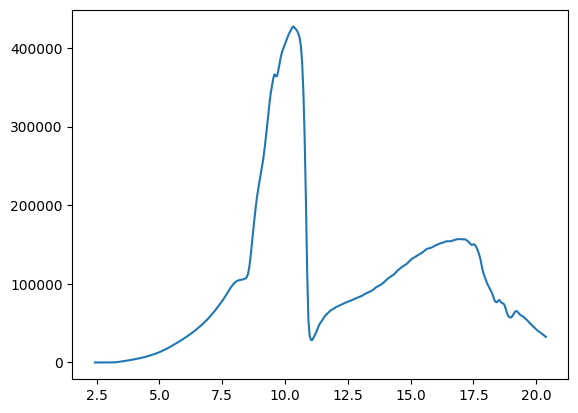

In [34]:
import matplotlib.pyplot as plt
plt.plot(model.E_fermis,fermi_scan[0])


In [21]:
cal_HV = make_k_hamiltonian_velocity_calculator(model)
cal_H = make_k_hamiltonian_calculator(model)
H0,V = cal_HV(jnp.array([0.01,0.1,0.3]))
Hc = cal_H(jnp.array([0.01,0.1,0.3]))
print(H0.shape)
print(V.shape)
val = jnp.linalg.eigvalsh(H0)
print(V[2,:,0])


Anomalous position term is not used,use partial only
(18, 18)
(18, 18, 3)
[-1.96089534e-04+5.16116908e-01j -5.00749753e-05+5.64169311e-02j
 -4.74258871e-01+2.22044605e-16j  3.55593630e-06+3.29525726e-06j
 -1.56477196e+01-3.76018635e-03j -9.71566269e-03-5.63414194e-02j
  1.25952689e-01+8.43144749e-02j  6.06968761e-02-3.23122507e-02j
 -1.65625473e-04+2.42587011e-02j  9.30049279e-06-7.96789177e-02j
 -2.31088920e-04-3.26609119e+00j -1.24386323e-02+1.29346669e-03j
 -3.51499584e-02-7.29673516e-03j -3.66602615e-03-1.24010760e-02j
 -1.54652399e-02+5.51857225e-02j -4.11424291e-04-3.55365882e-03j
  1.91032540e-03+3.49883696e-01j  1.10617080e-02-4.56237479e-03j]


In [23]:
model.O_list_kubo['Lz'][-1]

Array([0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
       0.+0.j, 0.+0.j, 0.-0.j, 0.-1.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
       0.+0.j, 0.+0.j], dtype=complex128)

In [29]:
L[:,:,-1].imag

Array([[ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.,  0., -1., -0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.,  0., -0., -1.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.,  0.,

# K space

In [5]:
# K space==============================BEGIN
def build_k_path(model:TB_model,
                 k_points:jnp.ndarray,
                 ticks_label:list[str],
                 length:int=100,
                 ):
    """
    build k path for given model
    param model: TB model
    param k_points: k points, shape (n_kpoints,3)
    param ticks_label: label for each tick, shape (n_kpoints,)
    param length: number of k points per path segment 
    it is a fix value so x coordinate of each k point is not evenly spaced
    return: k path, shape (n_kpoints,3)
    """
    # check k_points shape
    if k_points.shape[1] != 3:
        raise ValueError("k_points shape must be (n_kpoints,3)")
    n_path = k_points.shape[0] - 1
    if n_path < 1:
        raise ValueError("k_points must have at least 2 points")
    k_path = []   # all k points along path
    k_path_x = [] # x coordinate that used to plot path
    ticks = [] # xticks for plot
    X = 0
    for i in range(len(k_points)-1):
         k_start = k_points[i]
         k_end = k_points[i+1]
         interval = jnp.linalg.norm(k_end - k_start) / length # interval between two k points
         ticks.append(X)
         for j in jnp.arange(length):
             k_path.append(k_start + (k_end - k_start) * j / length)
             X += interval
             k_path_x.append(X)
    # the last point
    X += interval
    k_path_x.append(X)
    ticks.append(X)
    k_path.append(k_end)
    
    model.k_path = jnp.array(k_path)
    model.k_path_x = jnp.array(k_path_x)
    model.ticks = jnp.array(ticks)
    model.ticks_label = ticks_label

    return model.k_path,model.k_path_x,model.ticks,model.ticks_label

def build_k_mesh(model:TB_model,
                 nkx:int,
                 nky:int,
                 nkz:int,
                 ):
    """
    build k mesh for given model
    param model: TB model
    param nkx: k-mesh in x direction
    param nky: k-mesh in y direction
    param nkz: k-mesh in z direction
    return: k mesh, shape (nkx*nky*nkz,3)
    """
    nk = nkx * nky * nkz
    model.V_k = model.V/nk # normalize V to V_k

    k_mesh = jnp.meshgrid(jnp.linspace(0,1,nkx,endpoint=False),
                              jnp.linspace(0,1,nky,endpoint=False),
                              jnp.linspace(0,1,nkz,endpoint=False), 
                              indexing='ij')
    k_points = jnp.stack(k_mesh,axis=-1).reshape(-1,3)
    k_points = jnp.dot(k_points,model.recip_lattice)
    print(f"there are {nk} k points in k mesh")
    return k_points

#========================================END


# Calculators

In [6]:
# Calculators==================Begin

#hamiltonian in k space
# use functional factory to make a calculator
# it should be coupled, so just pass the data calss
from typing import Any


def make_k_hamiltonian_calculator(model: TB_model):
    cell_center = model.cell_center
    center_matrix = model.center_matrix
    HR = model.HR

    @jax.jit
    def _calculator(k:jnp.ndarray):
        '''
        calculate the hamiltonian in k space
        para:
            k: jnp.ndarray, # 3
        return:
            Hk: jnp.ndarray, # nwan * nwan
        '''
        # calculate the phase factor for each R
        # This phase is caused by the diffrent position of the cell center
        dot_product = jnp.einsum('ij,j->i', cell_center, k)
        Phase_R = jnp.exp(1j * dot_product) # nR

        # calculate the phase factor for each center diff
        # This phase is caused by the diffrent position of the WF within the unit cell
        dot_product = jnp.einsum('ijk,k->ij', center_matrix, k)
        Phase_W = jnp.exp(1j * dot_product) # nwan * nwan
        
        # part 1: use einsum to calculate the partial sum of Phase_R and HR
        partial_sum = jnp.einsum('i,ijk->jk', Phase_R, HR)
        # part 2: multiply the phase factor for each center diff
        Hk = partial_sum * Phase_W

        # make sure the hamiltonian is hermitian
        return (Hk + Hk.conj().T) / 2

    return _calculator


# a calculator for the velocity of the hamiltonian with respect to k
# it should be coupled, so just pass the model class
def make_k_hamiltonian_velocity_calculator(model: TB_model,use_A:bool=False):
    cell_center = model.cell_center
    center_matrix = model.center_matrix
    HR = model.HR
    AA_R = model.AA_R
    nwan = center_matrix.shape[0]

    if use_A:
        print("Anomalous position term is used")
    else:
        print("Anomalous position term is not used,use partial only")

    @jax.jit
    def _calculator(k:jnp.ndarray):
        '''
        calculate the velocity of the hamiltonian with respect to k
        para:
            k: jnp.ndarray, # 3
        return:
            Hk: jnp.ndarray, # nwan * nwan
            velocity_k: jnp.ndarray, # nwan * nwan * 3
        '''
        # calculate 2 phase factors
        dot_product = jnp.einsum('ij,j->i', cell_center, k)
        Phase_R = jnp.exp(1j * dot_product) # nR
        dot_product = jnp.einsum('ijk,k->ij', center_matrix, k)
        Phase_W = jnp.exp(1j * dot_product) # nwan * nwan

        # Hk hamiltonian in k space
        # part 1: use einsum to calculate the partial sum of Phase_R and HR
        partial_sum = jnp.einsum('i,ijk->jk', Phase_R, HR) # nwan * nwan   
        Hk = partial_sum * Phase_W
        Hk = (Hk + Hk.conj().T) / 2

        # There are 2 parts of derivative of Hk with respect to k
        # ∂H(k)/∂k_μ = i Σ_R e^{ik·(R+τ_ij)} (R_μ+τ_ij,μ) H(R)
        part1 = jnp.einsum('iab, i, ab, id -> abd', 
                            HR, 
                            Phase_R, 
                            Phase_W, 
                            cell_center
                            )
        # part 2: 
        part2 = jnp.einsum('iab, i, ab, abd -> abd', 
                            HR, 
                            Phase_R, 
                            Phase_W, 
                            center_matrix)  
        # dH/dk  = i (part1 - part2)
        Hk_derivative = 1j*(part1 + part2)

        if use_A:
            # A_{mn}(k) = -i ( <R|A|R>_{mn} - <R|A|R>_{nm}^* )
            partial_sum = jnp.einsum('i,ijkl->jkl', Phase_R, AA_R)
            temp = (partial_sum + partial_sum.transpose(1, 0, 2).conj()) / 2
            A_term = -1j * (jnp.einsum('ijl,jk->ikl',temp,Hk) - jnp.einsum('ij,jkl->ikl',Hk,temp))
            velocity_k = Hk_derivative + A_term
        else:
            velocity_k = Hk_derivative
        return Hk,velocity_k    
    return _calculator





 

def make_calc_inner(model: TB_model,kbT:float=0.0):
    '''
    make a calculator for the inner product of the operators
    param:
        model: TB_model, # the model class
        kbT: float, # the temperature in eV unit
    
    return:
        _calculator: function, # a calculator for the inner product of the operators
    
    This calculator calculates the inner product of the operators O with the wave function psi_n(k)
    in k space. The inner product is defined as:<psi_n(k)|O|psi_m(k)>
    if kbT< 1e-9, output  all of its states, otherwise output the fermi level scan result

    Tips:
    if operator O is a identity matrix, then the inner product represents the occupation number
    because <psi_n(k)|I|psi_m(k)> = <psi_n(k)|psi_m(k)> = delta_{n,m}
    after fermi scan, states below EF are occupied(1), and above EF are unoccupied(0)
    thus, the fermi scan results in the cumulative DOS, which is the integral of the DOS

    Similarly, if O is: diag([0,1,1,0,0,...]), where only some elements are 1, 
    then the PDOS (Partial Density of States for a specific orbital) can be calculated in this way.
    '''
    O_array = jnp.array(list(model.O_list_inner.values()))
    n_operators = O_array.shape[0]
    nwan = model.nwan
    if n_operators == 0:
        print("calculate only Energy")
    else:
        print(f"calculate the inner product of the operators: {model.O_list_inner.keys()}")

    # fermi scan
    if kbT > 1e-9:
        print(f"calculate the fermi scan with kbT = {kbT}")
        # check if E_fermis is set
        if model.E_fermis == None:
            raise ValueError("E_fermis not set, use set_E_fermis to set the Fermi energy")
        E_fermis = model.E_fermis
        E_min = E_fermis[0]
        E_max = E_fermis[-1]
        interval = E_fermis[1] - E_fermis[0]
        print(f"please confirm: E_min = {E_min}, E_max = {E_max}, interval = {interval}")
        scan = True
    else:
        # list of energy states, so E_fermis is not necessary
        print("do not calculate the fermi scan")
        scan = False

    hamiltonian_calculator = make_k_hamiltonian_calculator(model)

    # use jit
    # only k is dynamic, others are static
    @jax.jit
    def _calculator(k:jnp.ndarray):
        '''
        calculate the inner product of the operators
        para:
            k: jnp.ndarray, # 3
        return:
            inner_product: jnp.ndarray, physical values of one k-point
            it could be all of its states OR a fermi level scan result

        '''
        # calculate the hamiltonian in k space
        Hk = hamiltonian_calculator(k)
        if n_operators == 0:
            E_k = jnp.linalg.eigvalsh(Hk) # energy only
        else:
            E_k, Vec_k = jnp.linalg.eigh(Hk)
        
        if scan: 
            # a fermi distribution for each E_fermis[:]
            f_distribution = fermi_dirac_vamp(E_k,E_fermis,kbT) # nwan * len(E_fermis)
            result = jnp.zeros((n_operators+1,len(E_fermis)),dtype=default_type_real)
            temp = E_k[:,None] * f_distribution # nwan * len(E_fermis)
            result = result.at[0,:].set(jnp.sum(temp,axis=0)) # sum over nwan
            if n_operators > 0: # if O_list is not empty, this will do nothing 
                # use einsum to calculate the inner product of the operators
                # O_array is n_operators * nwan * nwan
                # Omega_array is n_operators * nwan
                # f_distribution is nwan * len(E_fermis)
                # the result is n_operators * len(E_fermis)
                Omega_array = jnp.einsum('ij,ajk,ki->ai',Vec_k.conj().T,O_array,Vec_k, optimize='optimal')
                temp = Omega_array.real[:,:,None] * f_distribution[None,:,:]
                result = result.at[1:,:].set(jnp.sum(temp,axis=1))
        else: 
            #output all of its states
            result = jnp.zeros((n_operators+1,nwan),dtype=default_type_real)
            result = result.at[0,:].set(E_k)
            if n_operators > 0: # if O_list is not empty, this will do nothing 
                #Omega_array is n_operators * nwan, take the real part
                Omega_array = jnp.einsum('ij,ajk,ki->ai',Vec_k.conj().T,O_array,Vec_k, optimize='optimal')
                result = result.at[1:,:].set(Omega_array.real)
        return result
    # end of _calculator

    
    return _calculator

def make_calc_kubo(
    model: TB_model,
    alpha:int = 0,#1st direction of kubo formula
    beta:int  = 1,#2nd direction of kubo formula
    Gamma:float = 0.025,# smearing width,in eV unit
    kbT:float=0.0, # in eV unit
    use_A:bool = False, # whether to use A_term, default is False
    ):
    '''
    make a calculator that calculates the kubo formula for the model
    para:
        model: TB_model, # the model to calculate
        alpha:int = 0,#1st direction of kubo formula
        beta:int  = 1,#2nd direction of kubo formula
        Gamma:float = 0.025,# smearing width,in eV unit
        kbT:float=0.0, # in eV unit
        use_A:bool = False, # whether to use A_term, default is False
    return:
        _calculator: a jitted function, # a calculator for the kubo formula
    '''

    O_array = jnp.array(list(model.O_list_kubo.values()))
    n_operators = O_array.shape[0]
    nwan = model.nwan

    if n_operators == 0:
        raise ValueError("O_list_kubo is empty, calculate nothing of kubo formula")
    else:
        print(f"calculate the kubo formula for the operators: {model.O_list_kubo.keys()}")
        Hk_Vk_calculator = make_k_hamiltonian_velocity_calculator(model,use_A)
    
    if kbT > 1e-9:
        print(f"calculate the fermi scan with kbT = {kbT}")
        # check if E_fermis is set
        if model.E_fermis == None:
            raise ValueError("E_fermis not set, use set_E_fermis to set the Fermi energy")
        E_fermis = model.E_fermis
        E_min = E_fermis[0]
        E_max = E_fermis[-1]
        interval = E_fermis[1] - E_fermis[0]
        print(f"please confirm: E_min = {E_min:.4f}, E_max = {E_max:.4f}, interval = {interval:.4f}")
        scan = True
    else:
        # list of energy states, so E_fermis is not necessary
        print("do not calculate the fermi scan")
        scan = False
    
    # An anonymous function that exists only within this function factory.
    def _cal_Omega(
        E_k:jnp.ndarray,
        Vec_k:jnp.ndarray,
        velocity_k:jnp.ndarray,
        ):
        '''
        calculate the Omega_k for the model
        para:
            E_k: jnp.ndarray, # nwan
            Vec_k: jnp.ndarray, # nwan * nwan
            velocity_k: jnp.ndarray, # nwan * nwan
        return:
            Omega_array: jnp.ndarray, # n_operators * nwan
        '''
        Vec_k_dagger = Vec_k.conj().T
        v_beta = velocity_k[:,:,beta]
        v_alpha = velocity_k[:,:,alpha]

        #term 2 for the kubo formula, it is O-independent
        v_beta_eb = Vec_k_dagger @ v_beta @ Vec_k

        # denominator for the kubo formula
        denominator = (E_k[None,:] - E_k[:,None])**2 + Gamma**2 +1e-12 # nwan * nwan
        # set to inf where n=m
        diag_indices = jnp.diag_indices(nwan)
        denominator = denominator.at[diag_indices].set(jnp.inf)

        # here we can use for loop, because n_operators is small
        Omega_array = jnp.zeros((n_operators,nwan),dtype=default_type_real)
        for i,O in enumerate(O_array):
            J_O = (0.5) * (O @ v_alpha + v_alpha @ O)
            # term1 is O dependent
            J_O_eb = Vec_k_dagger @ J_O @ Vec_k  # term1
            numerator = J_O_eb * v_beta_eb.T # term1 * term2: O[n,m] * v_beta[m,n]
            fraction = numerator / denominator # nwan * nwan
            # sum over n, and take the imaginary part
            Omega_array = Omega_array.at[i,:].set(-2 * jnp.imag(jnp.sum(fraction,axis=1))) 
        return Omega_array
            

    # jit the function
    @jax.jit
    def _calculator(
        k:jnp.ndarray,
        ):
        '''
        calculate the Omega_k for the model
        para:
            k: jnp.ndarray, # 3
        return:
            Omega_array: jnp.ndarray, # n_operators * nwan
        '''
        H_k, velocity_k = Hk_Vk_calculator(k)
        E_k,Vec_k = jnp.linalg.eigh(H_k)
        if scan:
                f_distribution = fermi_dirac_vamp(E_k,E_fermis,kbT) # nwan * len(E_fermis)
                Omega_array = _cal_Omega(E_k,Vec_k,velocity_k)
                temp = Omega_array.real[:,:,None] * f_distribution[None,:,:] # n_operators * nwan * len(E_fermis)
                # n_operators * len(E_fermis)
                result = jnp.sum(temp,axis=1)
        else:
            result = _cal_Omega(E_k,Vec_k,velocity_k)
        return result
    # end of _calculator
    return _calculator
        
# Calculators==================End



# IO functions

In [7]:
# io ================================ BEGIN
def read_TB_model(file_name: str) -> TB_model:
    """
    Read a TB model from a npz file.

    Parameters
    ----------
    file_name : str
        The name of the npz or pickle file.

    Returns
    -------
    TB_model
        The TB model.
    """

    # check file extension
    if file_name.endswith(".npz"):
        print (f"read_TB_model: read {file_name}")
        data = jnp.load(file_name)
        HR = data['HR']
        cell_center = data['cRvec']
        center_list = data['Wan_center']
        AA_R = data['AA_R']
        real_lattice = data['real_lattice']
        recip_lattice = data['recip_lattice']
        
        return TB_model(HR=HR,
                        cell_center=cell_center,
                        center_list=center_list,
                        AA_R=AA_R,
                        real_lattice=real_lattice,
                        recip_lattice=recip_lattice)
    elif file_name.endswith(".pickle"):
        import pickle
        with open(file_name, "rb") as f:
            model = pickle.load(f)
        return model
    else:
        raise ValueError(f"Unknown file extension {file_name}")


def save_TB_model(model: TB_model, file_name: str):
    """
    Save a TB model to a pickle file.

    Parameters
    ----------
    model : TB_model
        The TB model to be saved.
    file_name : str
        The name of the pickle file.
    """
    import pickle
    with open(file_name+".pickle", "wb") as f:
        pickle.dump(model, f)
# io ================================ END

# Operators

In [8]:
num_ao = { # num of atomic orbitals for each orbital type, considering spin
    's':2,
    'p':6,
    'd':10,
    'f':14, # no g orbital
}
# load pre-defined operator matrix
operator = jnp.load("operator.npz")

class operator_matrix_all:
    def __init__(self,orbital_list:list[str]):
        self.orbital_list = orbital_list
        self.orbital_all = build_operator_all(orbital_list)
        self.ndim = len(self.orbital_all)

        self.S,self.L,self.LS = build_operator_LS(orbital_list,use_LS_base=True)

        self.pre_prepared_operators = {
            'Sx' :self.S[:,:,0],
            'Sy' :self.S[:,:,1],
            'Sz' :self.S[:,:,2],
            'Lx' :self.L[:,:,0],
            'Ly' :self.L[:,:,1],
            'Lz' :self.L[:,:,2],
            'LS' :self.LS,
            "I"  :jnp.eye(self.ndim,dtype=default_type_real),
        }


    
    def make_P_easy(self,select_name:str):
        """
        make projection operator for given orbital name

        param select_name: name of the orbital, e.g. "s" or "p"
        return: projection operator, shape (norb,norb)
        """
        return build_P_easy(self.orbital_all,select_name)
    
    def make_POP_easy(self,select_name:str,pre_perpared_name:str):
        """
        make projection operator for given orbital name

        param select_name: name of the orbital, e.g. "s" or "p"
        param pre_perpared_name: name of the pre-prepared operator, e.g. "Sx" or "Ly"
        return: projected operator, P O P ,shape (norb,norb)
        """
        return build_P_easy(self.orbital_all,select_name) @ self.pre_prepared_operators[pre_perpared_name] @ build_P_easy(self.orbital_all,select_name) 

    def make_POP_pre_prepared(self,P_mat:jnp.ndarray,pre_perpared_name:str):
        """
        make projection operator for given orbital name

        param P_mat: projection operator, shape (norb,norb)
        param pre_perpared_name: name of the pre-prepared operator, e.g. "Sx" or "Ly"
        return: projected operator, P O P ,shape (norb,norb)
        """
        return P_mat @ self.pre_prepared_operators[pre_perpared_name] @ P_mat


# Function to build projection operator for given orbital list
def build_P_easy(orbital_all:list[str],selected:str):
    """
    build projection operator for given orbital list

    param orbital_list: list of orbital names, e.g. ["spd","p"]
    return: projection operator, shape (norb,norb)
    """
    select_list = [1 if o==selected else 0 for o in orbital_all]    
    return jnp.diag(jnp.array(select_list,dtype=default_type_real))


def build_operator_all(orbital_list:list[str]):
    """
    build operator name list for given orbital list

    param orbital_list: list of orbital names, e.g. ["spd","p"]
    return: operator name list repeat for each orbital type, 
    e.g. ["s","s","p","p","p","d","d","d"]
    """
    orbital_str = "".join(orbital_list)
    orbital_all = []
    for o in orbital_str:
        if o not in num_ao:
            raise ValueError(f"orbital type {o} not supported")
        num_repeat = num_ao[o]
        orbital_all.extend([o]*num_repeat)
 
    return orbital_all

def select_orbital_easy(orbital_name_list:list[str],selected:str):
    """
    select orbital (1 or 0) for given orbital name list

    param orbital_name_list: list of orbital names, e.g. ["s","s","p","p","p","d","d","d"]
    param orbital_name: name of the orbital, e.g. "s" or "p"
    return: same size list of 1 or 0, e.g. [1,1,0,0,0,1,1,1]
    """
    return [1 if o==selected else 0 for o in orbital_name_list]

def build_operator_LS(orbital_list:list[str],use_LS_base:bool=False):
    """
    build operator matrix for given orbital list

    param orbital_list: list of orbital names, e.g. ["spd","p","sd",'f']
    param use_LS_base: whether to use LS coupled base, 
    default False, using real Atomic orbital basis
    return: S,L in 3D array, shape (norb,norb,3) and LS in 2D array, shape (norb,norb)
    """
    orbital_str = "".join(orbital_list)

    orbital_all = []
    for o in orbital_str:
        if o not in num_ao:
            raise ValueError(f"orbital type {o} not supported")
        orbital_all.append(num_ao[o])
    
    # init operator matrix
    norb = sum(orbital_all)
    S = jnp.zeros((norb,norb,3),dtype=default_type_complex)
    L = jnp.zeros((norb,norb,3),dtype=default_type_complex)

    # choose which operator matrix to use
    if use_LS_base:
        S_all = operator["S_LS"]
        L_all = operator["L_LS"]
    else:
        S_all = operator["S"]
        L_all = operator["L"]

    # seperate each orbitals into a dictionary
    S_AO = {
        2:S_all[0:2,0:2,:], # 2
        6:S_all[2:8,2:8,:], # 6
        10:S_all[8:18,8:18,:], # 10
        14:S_all[18:32,18:32,:], # 14    
    }
    L_AO = {
        2:L_all[0:2,0:2,:],# 2
        6:L_all[2:8,2:8,:],# 6
        10:L_all[8:18,8:18,:],# 10  
        14:L_all[18:32,18:32,:],# 14
    }  

    # fill L and S matrix
    i = 0
    for n_ao in orbital_all:
        start = i
        end = i + n_ao
        S = S.at[start:end,start:end,:].set(S_AO[n_ao])
        L = L.at[start:end,start:end,:].set(L_AO[n_ao])
        i = end
    
    # L dot S
    LS = L[:,:,0] @ S[:,:,0] + L[:,:,1] @ S[:,:,1] + L[:,:,2] @ S[:,:,2]

    return S,L,LS


# test
if __name__ == "__main__":
    orbital_list = ["spd"]
    S,L,LS = build_operator_LS(orbital_list,use_LS_base=True)
    test1 = operator_matrix_all(['spd'])
    print(test1.orbital_all)
    print(test1.pre_prepared_operators.keys())
    print(test1.pre_prepared_operators["LS"].shape)

    O_test_P = test1.make_P_easy("s")
    print(jnp.diag(O_test_P))


['s', 's', 'p', 'p', 'p', 'p', 'p', 'p', 'd', 'd', 'd', 'd', 'd', 'd', 'd', 'd', 'd', 'd']
dict_keys(['Sx', 'Sy', 'Sz', 'Lx', 'Ly', 'Lz', 'LS', 'I'])
(18, 18)
[1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


# test

In [9]:
model = read_TB_model("TB.npz")
# test save
save_TB_model(model, "test")

# test load
model2 = read_TB_model("test.pickle")

# test set EF
model2.set_EF("Cu.scf.out")


read_TB_model: read TB.npz
TB_model: nwan=18, nR=617
EF=12.43
